# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Muhammad Zaki Nanda Wahyudi | 5054251007 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [22]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Set random seed dengan torch.manual_seed(42) dan np.random.seed(42).
# Tentukan device: device = "cuda" if torch.cuda.is_available() else "cpu", lalu tampilkan device yang digunakan.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, precision_recall_fscore_support
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset

# Set random seed
torch.manual_seed(42)
np.random.seed(42)

# Tentukan device
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device yang digunakan: {device}")

Device yang digunakan: cpu


In [3]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.

train_df = pd.read_csv("fashion-mnist_train.csv")
test_df = pd.read_csv("fashion-mnist_test.csv")

print("Ukuran data train:", train_df.shape)
print("Ukuran data test :", test_df.shape)

Ukuran data train: (60000, 785)
Ukuran data test : (10000, 785)


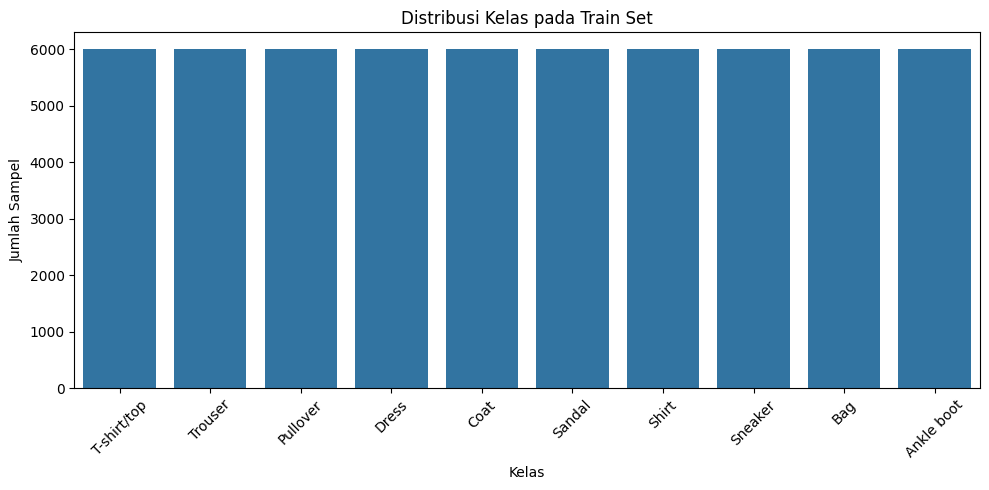

In [4]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.

class_names = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot",
}

class_counts = train_df["label"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
sns.barplot(x=[class_names[i] for i in class_counts.index], y=class_counts.values)
plt.title("Distribusi Kelas pada Train Set")
plt.xlabel("Kelas")
plt.ylabel("Jumlah Sampel")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

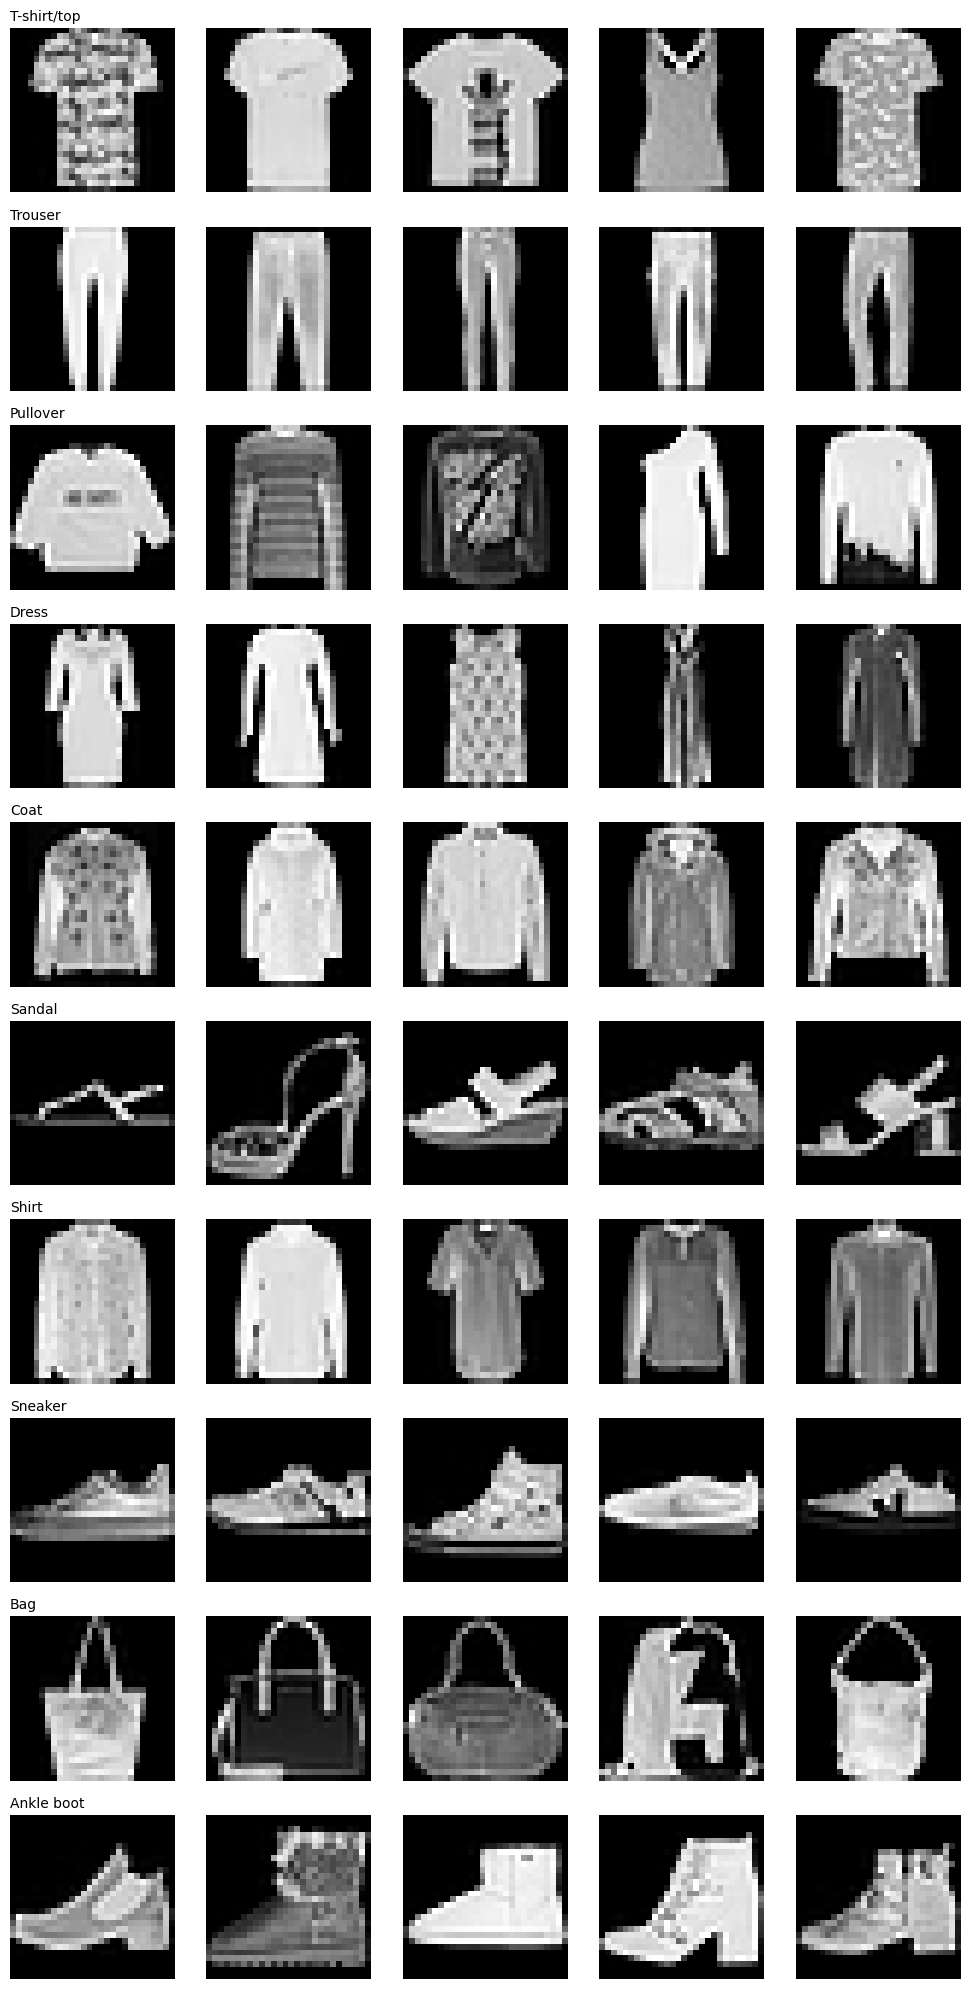

In [5]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?

n_per_class = 5

fig, axes = plt.subplots(10, n_per_class, figsize=(n_per_class * 2, 20))

for label in range(10):
    samples = train_df[train_df["label"] == label].head(n_per_class)
    for j, (_, row) in enumerate(samples.iterrows()):
        img = row.drop("label").values.reshape(28, 28)
        ax = axes[label, j]
        ax.imshow(img, cmap="gray")
        ax.axis("off")
        if j == 0:
            ax.set_title(class_names[label], fontsize=10, loc="left")

plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

Missing value train: 0
Missing value test : 0
Tipe data train: [dtype('int64')]
Tipe data test : [dtype('int64')]
Rentang piksel train: 0 - 255
Rentang piksel test : 0 - 255


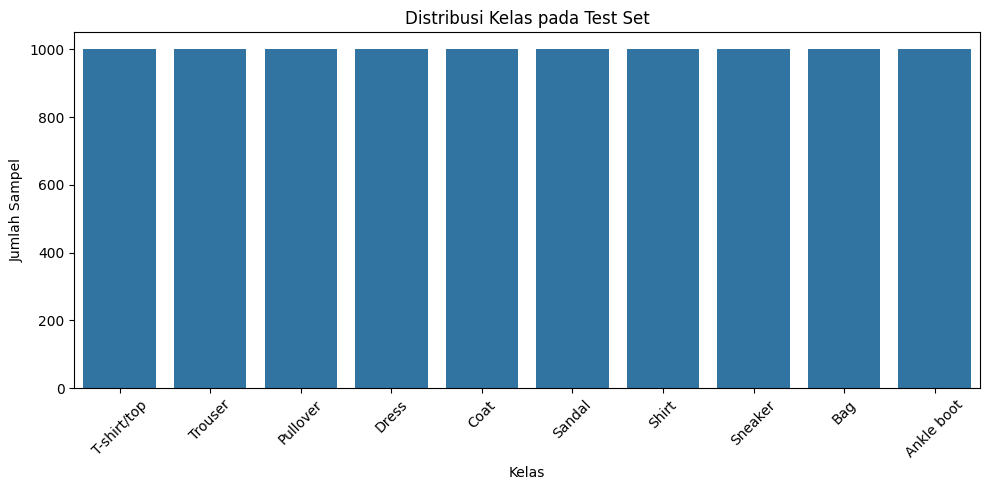

Jumlah kolom train: 785
Jumlah kolom test : 785
Nama kolom sama   : True
Mean piksel train: 0.2861052180872349
Std piksel train : 0.35281122739263177


In [6]:
# 1. Missing value dan tipe data
print("Missing value train:", train_df.isnull().sum().sum())
print("Missing value test :", test_df.isnull().sum().sum())
print("Tipe data train:", train_df.dtypes.unique())
print("Tipe data test :", test_df.dtypes.unique())

# 2. Rentang nilai piksel
pixel_cols_train = train_df.drop(columns="label")
pixel_cols_test = test_df.drop(columns="label")
print("Rentang piksel train:", pixel_cols_train.values.min(), "-", pixel_cols_train.values.max())
print("Rentang piksel test :", pixel_cols_test.values.min(), "-", pixel_cols_test.values.max())

# 3. Distribusi kelas pada test set
test_class_counts = test_df["label"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
sns.barplot(x=[class_names[i] for i in test_class_counts.index], y=test_class_counts.values)
plt.title("Distribusi Kelas pada Test Set")
plt.xlabel("Kelas")
plt.ylabel("Jumlah Sampel")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 4. Kesamaan struktur train dan test
print("Jumlah kolom train:", train_df.shape[1])
print("Jumlah kolom test :", test_df.shape[1])
print("Nama kolom sama   :", list(train_df.columns) == list(test_df.columns))

# 5. Mean dan std piksel (dihitung dari train, skala 0-1)
pixel_values = pixel_cols_train.values / 255.0
print("Mean piksel train:", pixel_values.mean())
print("Std piksel train :", pixel_values.std())

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [7]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.

X_train = train_df.drop(columns="label").values
y_train = train_df["label"].values

X_test = test_df.drop(columns="label").values
y_test = test_df["label"].values

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape, "| y_test :", y_test.shape)

X_train: (60000, 784) | y_train: (60000,)
X_test : (10000, 784) | y_test : (10000,)


In [8]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).

X_train = X_train / 255.0
X_test = X_test / 255.0

print("Rentang X_train:", X_train.min(), "-", X_train.max())
print("Rentang X_test :", X_test.min(), "-", X_test.max())

Rentang X_train: 0.0 - 1.0
Rentang X_test : 0.0 - 1.0


In [9]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size=0.1,
    stratify=y_train,
    random_state=42
)

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val  :", X_val.shape, "| y_val  :", y_val.shape)
print("X_test :", X_test.shape, "| y_test :", y_test.shape)

X_train: (54000, 784) | y_train: (54000,)
X_val  : (6000, 784) | y_val  : (6000,)
X_test : (10000, 784) | y_test : (10000,)


In [10]:
# Ubah data menjadi tensor: X bertipe torch.float32 dengan bentuk (N, 1, 28, 28), y bertipe torch.long (wajib untuk nn.CrossEntropyLoss).
# Buat DataLoader untuk train, validation, dan test menggunakan TensorDataset (shuffle=True hanya untuk train).

# Ubah ke tensor
X_train_t = torch.tensor(X_train, dtype=torch.float32).reshape(-1, 1, 28, 28)
X_val_t = torch.tensor(X_val, dtype=torch.float32).reshape(-1, 1, 28, 28)
X_test_t = torch.tensor(X_test, dtype=torch.float32).reshape(-1, 1, 28, 28)

y_train_t = torch.tensor(y_train, dtype=torch.long)
y_val_t = torch.tensor(y_val, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)

print("X_train_t:", X_train_t.shape, X_train_t.dtype)
print("y_train_t:", y_train_t.shape, y_train_t.dtype)

# Buat DataLoader
batch_size = 64

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=batch_size, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=batch_size, shuffle=False)

X_train_t: torch.Size([54000, 1, 28, 28]) torch.float32
y_train_t: torch.Size([54000]) torch.int64


# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [11]:
# Definisikan arsitektur ANN sebagai class turunan nn.Module, lalu pindahkan ke device dengan model.to(device).
# Tampilkan arsitektur model dengan print(model) dan jumlah parameternya: sum(p.numel() for p in model.parameters()).

class ANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

model = ANN().to(device)

print(model)
print("Jumlah parameter:", sum(p.numel() for p in model.parameters()))

ANN(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 235146


In [13]:
# Tentukan loss function (nn.CrossEntropyLoss), optimizer, learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Setiap batch harus dipindahkan ke device yang sama dengan model (x.to(device), y.to(device)).
# Di akhir setiap epoch, hitung loss dan accuracy train dan validation (gunakan model.eval() dan torch.no_grad()), simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.2 dan 3.3.

# Hyperparameter
criterion = nn.CrossEntropyLoss()
learning_rate = 0.001
num_epochs = 10
batch_size = 64  # sudah dipakai saat membuat DataLoader

def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            outputs = model(x)
            loss = criterion(outputs, y)
            total_loss += loss.item() * x.size(0)
            correct += (outputs.argmax(dim=1) == y).sum().item()
            total += y.size(0)
    return total_loss / total, correct / total

def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs):
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(num_epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            outputs = model(x)
            loss = criterion(outputs, y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * x.size(0)
            correct += (outputs.argmax(dim=1) == y).sum().item()
            total += y.size(0)

        train_loss = running_loss / total
        train_acc = correct / total
        val_loss, val_acc = evaluate(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch+1}/{num_epochs} | "
              f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

    return history

optimizer = optim.Adam(model.parameters(), lr=learning_rate)

history = train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs)

Epoch 1/10 | Train Loss: 0.5435, Train Acc: 0.8057 | Val Loss: 0.4407, Val Acc: 0.8387
Epoch 2/10 | Train Loss: 0.3825, Train Acc: 0.8594 | Val Loss: 0.3707, Val Acc: 0.8628
Epoch 3/10 | Train Loss: 0.3406, Train Acc: 0.8751 | Val Loss: 0.3542, Val Acc: 0.8715
Epoch 4/10 | Train Loss: 0.3175, Train Acc: 0.8842 | Val Loss: 0.3285, Val Acc: 0.8810
Epoch 5/10 | Train Loss: 0.2964, Train Acc: 0.8894 | Val Loss: 0.3326, Val Acc: 0.8790
Epoch 6/10 | Train Loss: 0.2815, Train Acc: 0.8948 | Val Loss: 0.3210, Val Acc: 0.8852
Epoch 7/10 | Train Loss: 0.2670, Train Acc: 0.9004 | Val Loss: 0.3183, Val Acc: 0.8835
Epoch 8/10 | Train Loss: 0.2561, Train Acc: 0.9038 | Val Loss: 0.3079, Val Acc: 0.8892
Epoch 9/10 | Train Loss: 0.2433, Train Acc: 0.9086 | Val Loss: 0.3233, Val Acc: 0.8870
Epoch 10/10 | Train Loss: 0.2329, Train Acc: 0.9116 | Val Loss: 0.3288, Val Acc: 0.8827


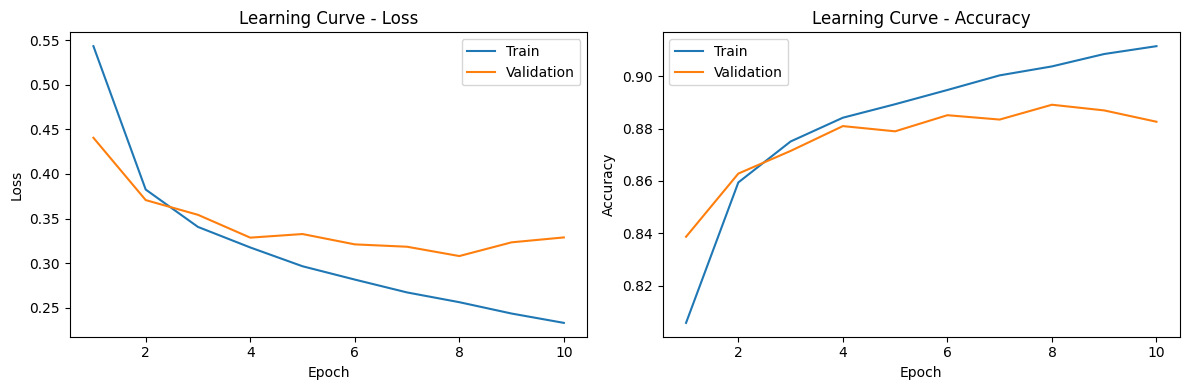

In [14]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.

epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss
axes[0].plot(epochs_range, history["train_loss"], label="Train")
axes[0].plot(epochs_range, history["val_loss"], label="Validation")
axes[0].set_title("Learning Curve - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# Accuracy
axes[1].plot(epochs_range, history["train_acc"], label="Train")
axes[1].plot(epochs_range, history["val_acc"], label="Validation")
axes[1].set_title("Learning Curve - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

In [15]:
# Lakukan prediksi pada test set dengan model.eval() dan torch.no_grad().
# Ambil kelas dengan nilai output terbesar menggunakan argmax(dim=1). Simpan hasil prediksi label dalam bentuk numpy array.

model.eval()
all_preds = []

with torch.no_grad():
    for x, _ in test_loader:
        x = x.to(device)
        outputs = model(x)
        preds = outputs.argmax(dim=1)
        all_preds.append(preds.cpu())

y_pred = torch.cat(all_preds).numpy()

print("Bentuk y_pred:", y_pred.shape)

Bentuk y_pred: (10000,)


## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [16]:
# Definisikan arsitektur CNN sederhana sebagai class turunan nn.Module (gunakan nn.Conv2d, nn.MaxPool2d, nn.Flatten, dan nn.Linear).
# Tampilkan arsitektur model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1.
# Hasil perhitungan ini menentukan ukuran input nn.Linear pertama setelah Flatten (channel × tinggi × lebar).
# Cocokkan dengan mengirim satu tensor dummy torch.zeros(1, 1, 28, 28) ke bagian konvolusi dan cetak bentuk outputnya.

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

cnn_model = CNN().to(device)

print(cnn_model)
print("Jumlah parameter:", sum(p.numel() for p in cnn_model.parameters()))

# Hitung manual ukuran output dengan rumus (W - K + 2P) / S + 1
def out_size(W, K, P, S):
    return (W - K + 2 * P) // S + 1

W = 28
W = out_size(W, K=3, P=1, S=1)
print("Setelah Conv2d(1, 32, 3, padding=1)  :", (32, W, W))
W = out_size(W, K=2, P=0, S=2)
print("Setelah MaxPool2d(2)                 :", (32, W, W))
W = out_size(W, K=3, P=1, S=1)
print("Setelah Conv2d(32, 64, 3, padding=1) :", (64, W, W))
W = out_size(W, K=2, P=0, S=2)
print("Setelah MaxPool2d(2)                 :", (64, W, W))
print("Input nn.Linear pertama (64 x W x W) :", 64 * W * W)

# Cocokkan dengan tensor dummy
dummy = torch.zeros(1, 1, 28, 28).to(device)
with torch.no_grad():
    print("Bentuk output bagian konvolusi (dummy):", cnn_model.features(dummy).shape)

CNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 421642
Setelah Conv2d(1, 32, 3, padding=1)  : (32, 28, 28)
Setelah MaxPool2d(2)                 : (32, 14, 14)
Setelah Conv2d(32, 64, 3, padding=1) : (64, 14, 14)
Setelah MaxPool2d(2)                 : (64, 7, 7)
Input nn.Linear pertama (64 x W x W) : 3136
Bentuk output bagian konvolusi (dummy): torch.Size([1, 64, 7, 7])


Epoch 1/10 | Train Loss: 0.4707, Train Acc: 0.8274 | Val Loss: 0.3258, Val Acc: 0.8785
Epoch 2/10 | Train Loss: 0.2996, Train Acc: 0.8926 | Val Loss: 0.2987, Val Acc: 0.8933
Epoch 3/10 | Train Loss: 0.2536, Train Acc: 0.9075 | Val Loss: 0.2745, Val Acc: 0.8983
Epoch 4/10 | Train Loss: 0.2197, Train Acc: 0.9188 | Val Loss: 0.2370, Val Acc: 0.9137
Epoch 5/10 | Train Loss: 0.1957, Train Acc: 0.9273 | Val Loss: 0.2349, Val Acc: 0.9153
Epoch 6/10 | Train Loss: 0.1747, Train Acc: 0.9362 | Val Loss: 0.2257, Val Acc: 0.9193
Epoch 7/10 | Train Loss: 0.1546, Train Acc: 0.9431 | Val Loss: 0.2175, Val Acc: 0.9232
Epoch 8/10 | Train Loss: 0.1354, Train Acc: 0.9508 | Val Loss: 0.2316, Val Acc: 0.9213
Epoch 9/10 | Train Loss: 0.1177, Train Acc: 0.9565 | Val Loss: 0.2248, Val Acc: 0.9250
Epoch 10/10 | Train Loss: 0.1032, Train Acc: 0.9616 | Val Loss: 0.2493, Val Acc: 0.9202


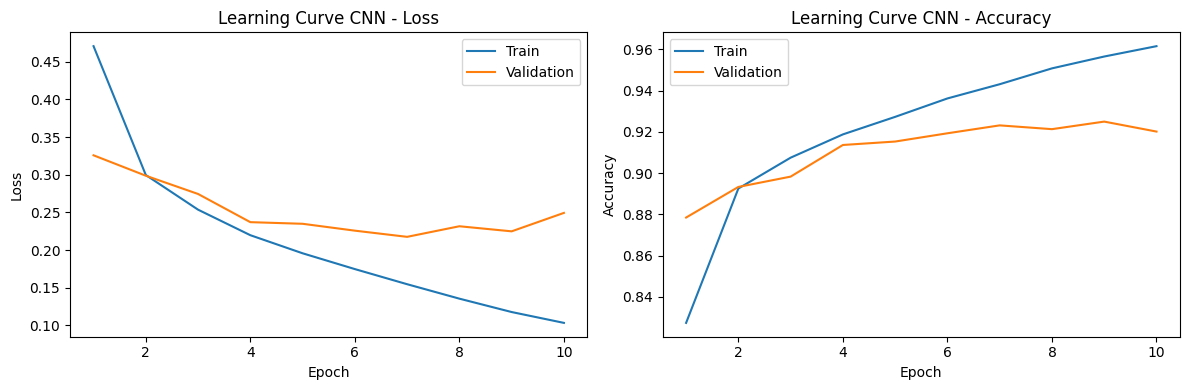

In [17]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.

optimizer_cnn = optim.Adam(cnn_model.parameters(), lr=learning_rate)

history_cnn = train_model(cnn_model, train_loader, val_loader, criterion, optimizer_cnn, num_epochs)

# Learning curve
epochs_range = range(1, len(history_cnn["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss
axes[0].plot(epochs_range, history_cnn["train_loss"], label="Train")
axes[0].plot(epochs_range, history_cnn["val_loss"], label="Validation")
axes[0].set_title("Learning Curve CNN - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# Accuracy
axes[1].plot(epochs_range, history_cnn["train_acc"], label="Train")
axes[1].plot(epochs_range, history_cnn["val_acc"], label="Validation")
axes[1].set_title("Learning Curve CNN - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

In [18]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

cnn_model.eval()
all_preds_cnn = []

with torch.no_grad():
    for x, _ in test_loader:
        x = x.to(device)
        outputs = cnn_model(x)
        preds = outputs.argmax(dim=1)
        all_preds_cnn.append(preds.cpu())

y_pred_cnn = torch.cat(all_preds_cnn).numpy()

print("Bentuk y_pred_cnn:", y_pred_cnn.shape)

Bentuk y_pred_cnn: (10000,)


## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [19]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: nn.Conv2d -> nn.BatchNorm2d(jumlah_channel_output) -> nn.ReLU -> nn.MaxPool2d.
# Tambahkan nn.Dropout(p) sebelum layer output.
# Ingat: BatchNorm dan Dropout berperilaku berbeda saat training dan evaluasi, pastikan memanggil model.train() dan model.eval() di tempat yang tepat.
# Tampilkan arsitektur model beserta jumlah parameternya.

class CNN_BN_Dropout(nn.Module):
    def __init__(self, dropout_p=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(dropout_p),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

cnn_bn_model = CNN_BN_Dropout(dropout_p=0.5).to(device)

print(cnn_bn_model)
print("Jumlah parameter:", sum(p.numel() for p in cnn_bn_model.parameters()))

CNN_BN_Dropout(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 421834


Epoch 1/10 | Train Loss: 0.5320, Train Acc: 0.8059 | Val Loss: 0.3343, Val Acc: 0.8770
Epoch 2/10 | Train Loss: 0.3696, Train Acc: 0.8686 | Val Loss: 0.2872, Val Acc: 0.8963
Epoch 3/10 | Train Loss: 0.3221, Train Acc: 0.8844 | Val Loss: 0.2633, Val Acc: 0.9070
Epoch 4/10 | Train Loss: 0.2917, Train Acc: 0.8956 | Val Loss: 0.2609, Val Acc: 0.9072
Epoch 5/10 | Train Loss: 0.2670, Train Acc: 0.9042 | Val Loss: 0.2344, Val Acc: 0.9183
Epoch 6/10 | Train Loss: 0.2530, Train Acc: 0.9091 | Val Loss: 0.2305, Val Acc: 0.9207
Epoch 7/10 | Train Loss: 0.2336, Train Acc: 0.9157 | Val Loss: 0.2300, Val Acc: 0.9218
Epoch 8/10 | Train Loss: 0.2239, Train Acc: 0.9191 | Val Loss: 0.2381, Val Acc: 0.9195
Epoch 9/10 | Train Loss: 0.2089, Train Acc: 0.9238 | Val Loss: 0.2363, Val Acc: 0.9170
Epoch 10/10 | Train Loss: 0.1962, Train Acc: 0.9272 | Val Loss: 0.2390, Val Acc: 0.9173


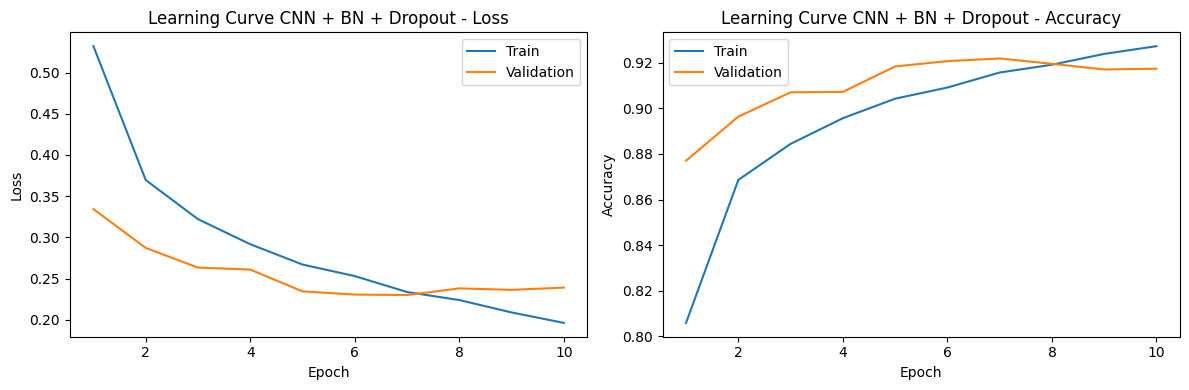

Selisih accuracy (train - val) CNN 3.2          : 0.0414
Selisih accuracy (train - val) CNN + BN + Dropout: 0.0099


In [20]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.

optimizer_bn = optim.Adam(cnn_bn_model.parameters(), lr=learning_rate)

history_bn = train_model(cnn_bn_model, train_loader, val_loader, criterion, optimizer_bn, num_epochs)

# Learning curve
epochs_range = range(1, len(history_bn["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss
axes[0].plot(epochs_range, history_bn["train_loss"], label="Train")
axes[0].plot(epochs_range, history_bn["val_loss"], label="Validation")
axes[0].set_title("Learning Curve CNN + BN + Dropout - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# Accuracy
axes[1].plot(epochs_range, history_bn["train_acc"], label="Train")
axes[1].plot(epochs_range, history_bn["val_acc"], label="Validation")
axes[1].set_title("Learning Curve CNN + BN + Dropout - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

# Selisih train vs validation pada epoch terakhir, dibandingkan dengan model 3.2
gap_cnn = history_cnn["train_acc"][-1] - history_cnn["val_acc"][-1]
gap_bn = history_bn["train_acc"][-1] - history_bn["val_acc"][-1]
print(f"Selisih accuracy (train - val) CNN 3.2          : {gap_cnn:.4f}")
print(f"Selisih accuracy (train - val) CNN + BN + Dropout: {gap_bn:.4f}")

In [21]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

cnn_bn_model.eval()
all_preds_bn = []

with torch.no_grad():
    for x, _ in test_loader:
        x = x.to(device)
        outputs = cnn_bn_model(x)
        preds = outputs.argmax(dim=1)
        all_preds_bn.append(preds.cpu())

y_pred_bn = torch.cat(all_preds_bn).numpy()

print("Bentuk y_pred_bn:", y_pred_bn.shape)

Bentuk y_pred_bn: (10000,)


# 4. Evaluasi Model

In [23]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.

def hitung_metrik(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return acc, prec, rec, f1

def jumlah_param(m):
    return sum(p.numel() for p in m.parameters())

hasil = {
    "ANN": (y_pred, model),
    "CNN Sederhana": (y_pred_cnn, cnn_model),
    "CNN + BN + Dropout": (y_pred_bn, cnn_bn_model),
}

rows = []
for nama, (pred, m) in hasil.items():
    acc, prec, rec, f1 = hitung_metrik(y_test, pred)
    rows.append({
        "Model": nama,
        "Accuracy": acc,
        "Precision (macro)": prec,
        "Recall (macro)": rec,
        "F1-Score (macro)": f1,
        "Jumlah Parameter": jumlah_param(m),
    })

tabel_perbandingan = pd.DataFrame(rows).set_index("Model")
display(tabel_perbandingan.round(4))

,Accuracy,Precision (macro),Recall (macro),F1-Score (macro),Jumlah Parameter
Model,,,,,
ANN,0.8862,0.8887,0.8862,0.8848,235146
CNN Sederhana,0.9235,0.9266,0.9235,0.9243,421642
CNN + BN + Dropout,0.9212,0.9226,0.9212,0.9208,421834


In [24]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.

nama_kelas = [class_names[i] for i in range(10)]

print("Classification Report - CNN Sederhana\n")
print(classification_report(y_test, y_pred_cnn, target_names=nama_kelas, digits=4))

Classification Report - CNN Sederhana

              precision    recall  f1-score   support

 T-shirt/top     0.8703    0.8790    0.8746      1000
     Trouser     0.9930    0.9930    0.9930      1000
    Pullover     0.9188    0.8370    0.8760      1000
       Dress     0.9359    0.9350    0.9355      1000
        Coat     0.9099    0.8480    0.8778      1000
      Sandal     0.9782    0.9860    0.9821      1000
       Shirt     0.7291    0.8450    0.7828      1000
     Sneaker     0.9669    0.9630    0.9649      1000
         Bag     0.9929    0.9800    0.9864      1000
  Ankle boot     0.9709    0.9690    0.9700      1000

    accuracy                         0.9235     10000
   macro avg     0.9266    0.9235    0.9243     10000
weighted avg     0.9266    0.9235    0.9243     10000



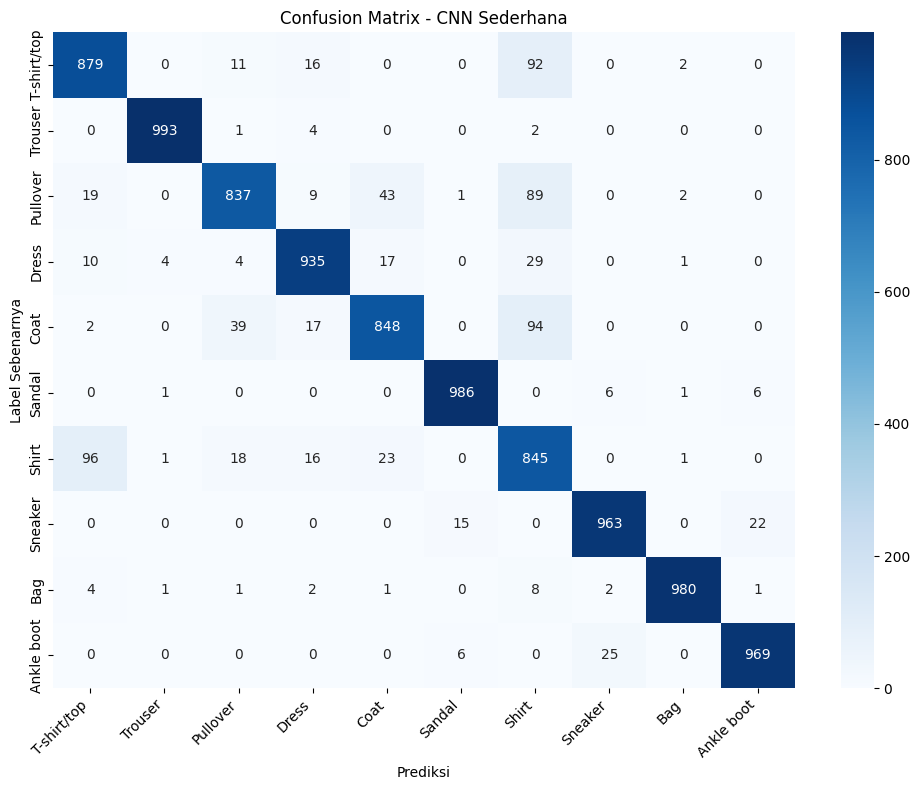

5 kesalahan terbanyak (label asli -> diprediksi):
Shirt -> T-shirt/top: 96 sampel
Coat -> Shirt: 94 sampel
T-shirt/top -> Shirt: 92 sampel
Pullover -> Shirt: 89 sampel
Pullover -> Coat: 43 sampel


In [25]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?

cm = confusion_matrix(y_test, y_pred_cnn)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=nama_kelas, yticklabels=nama_kelas)
plt.title("Confusion Matrix - CNN Sederhana")
plt.xlabel("Prediksi")
plt.ylabel("Label Sebenarnya")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Pasangan kelas yang paling sering tertukar (di luar diagonal)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)

pasangan = []
for i in range(10):
    for j in range(10):
        if i != j:
            pasangan.append((cm_off[i, j], class_names[i], class_names[j]))

pasangan.sort(reverse=True)
print("5 kesalahan terbanyak (label asli -> diprediksi):")
for jumlah, asli, prediksi in pasangan[:5]:
    print(f"{asli} -> {prediksi}: {jumlah} sampel")

Jumlah salah klasifikasi: 765


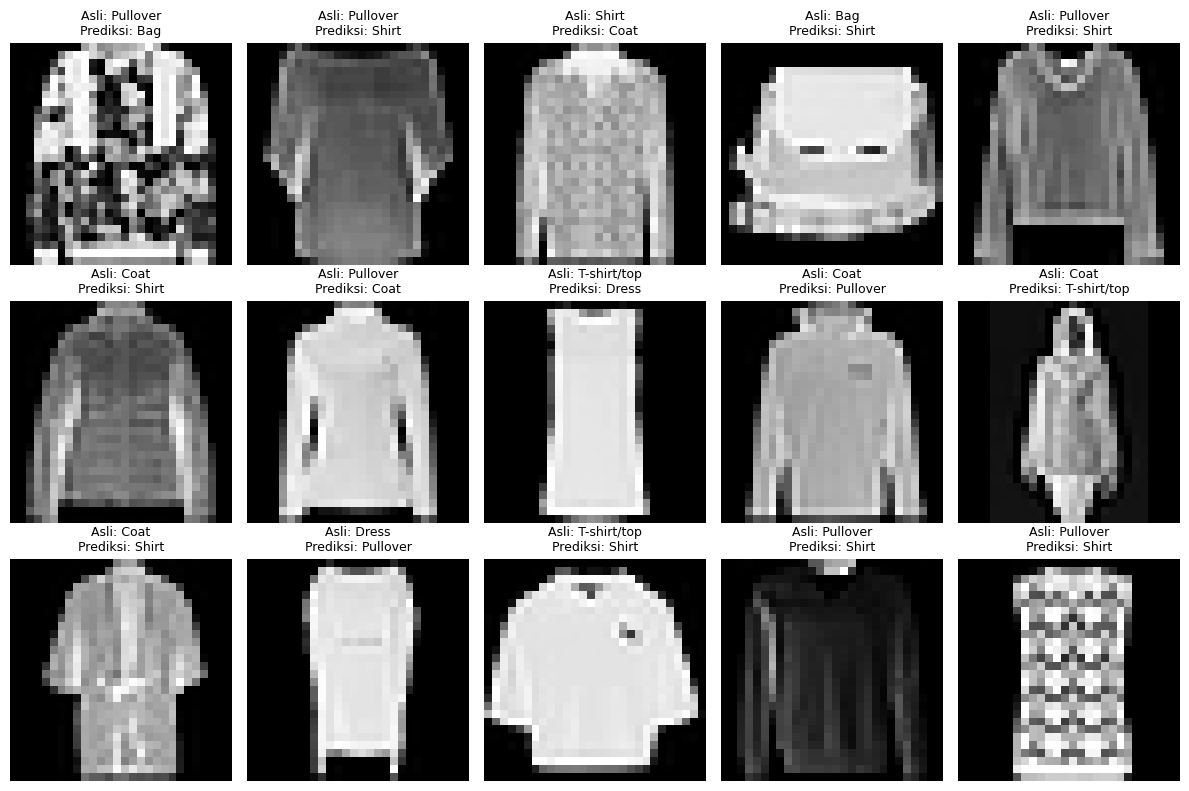

In [26]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.

# Cari indeks sampel yang salah diklasifikasikan oleh CNN Sederhana
salah_idx = np.where(y_pred_cnn != y_test)[0]
print("Jumlah salah klasifikasi:", len(salah_idx))

# Tampilkan 15 contoh pertama
n_tampil = 15
contoh_idx = salah_idx[:n_tampil]

fig, axes = plt.subplots(3, 5, figsize=(12, 8))

for ax, idx in zip(axes.flatten(), contoh_idx):
    ax.imshow(X_test[idx].reshape(28, 28), cmap="gray")
    ax.set_title(f"Asli: {class_names[y_test[idx]]}\nPrediksi: {class_names[y_pred_cnn[idx]]}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

Bentuk feature map: (32, 28, 28)


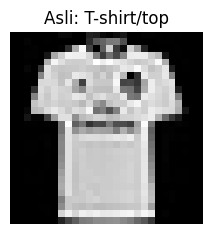

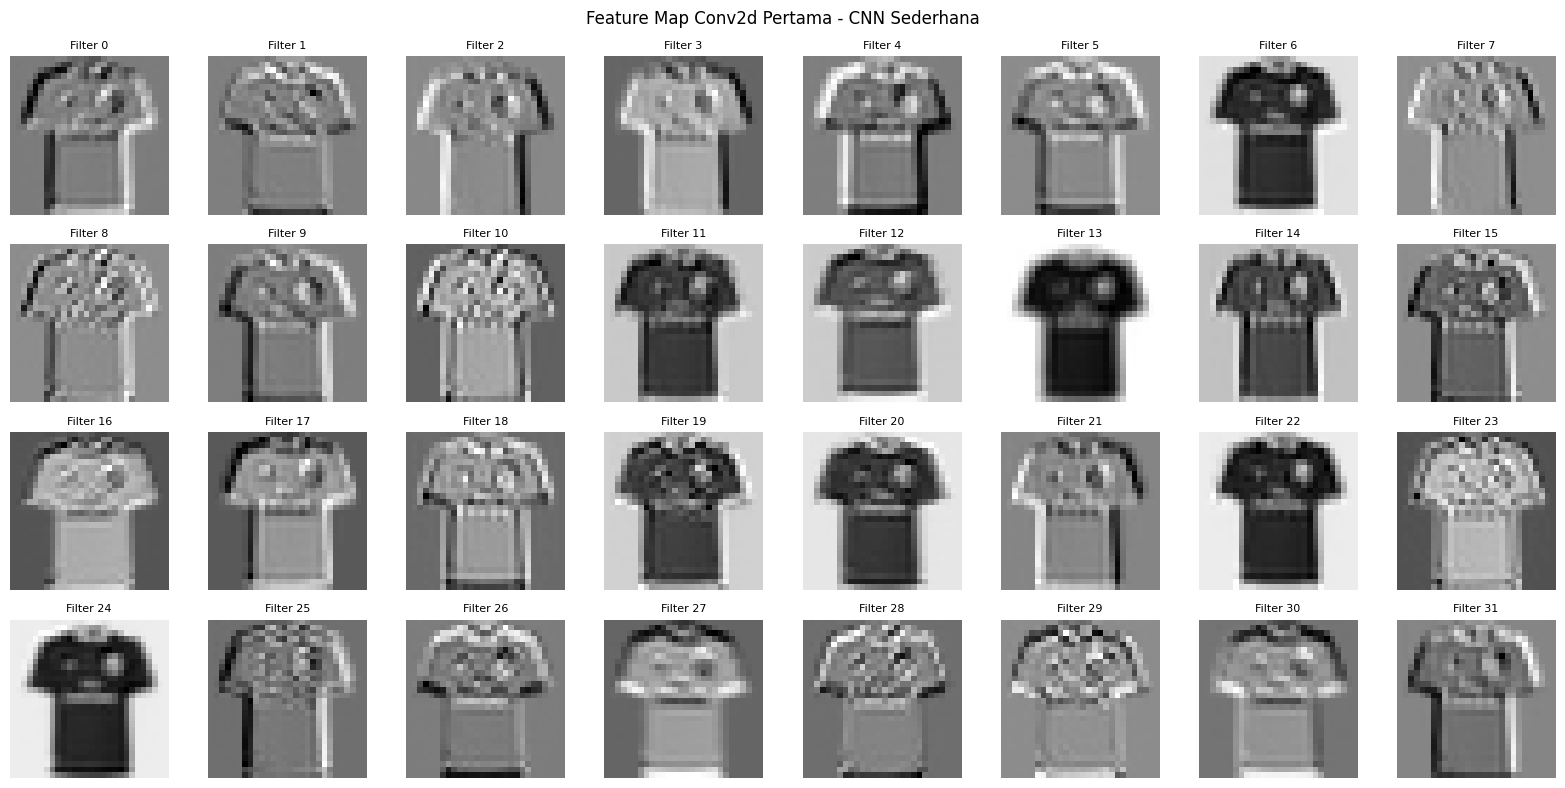

In [27]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Kirim satu gambar (bentuk (1, 1, 28, 28)) ke layer konvolusi pertama saja, misalnya model.features[0](x) jika menggunakan nn.Sequential bernama features,
# lalu tampilkan setiap channel output-nya sebagai gambar (gunakan .detach().cpu().numpy()).
# Apa saja pola yang ditangkap oleh masing-masing filter?

cnn_model.eval()

# Satu gambar contoh dari test set, bentuk (1, 1, 28, 28)
idx_contoh = 0
x = X_test_t[idx_contoh:idx_contoh + 1].to(device)

# Kirim hanya ke layer konvolusi pertama
with torch.no_grad():
    fmap = cnn_model.features[0](x)

fmap = fmap.detach().cpu().numpy()[0]  # bentuk (32, 28, 28)
print("Bentuk feature map:", fmap.shape)

# Gambar asli
plt.figure(figsize=(2.5, 2.5))
plt.imshow(X_test[idx_contoh].reshape(28, 28), cmap="gray")
plt.title(f"Asli: {class_names[y_test[idx_contoh]]}")
plt.axis("off")
plt.show()

# Feature map tiap channel (32 filter)
fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(fmap[i], cmap="gray")
    ax.set_title(f"Filter {i}", fontsize=8)
    ax.axis("off")

plt.suptitle("Feature Map Conv2d Pertama - CNN Sederhana")
plt.tight_layout()
plt.show()

In [28]:
# Simpan bobot model terbaik dengan torch.save(model.state_dict(), "model.pth").
# Model ini akan digunakan kembali pada tugas Deployment, jadi simpan juga definisi class model kalian.

# Simpan bobot model terbaik (CNN Sederhana)
torch.save(cnn_model.state_dict(), "model.pth")

# Simpan definisi class model ke file Python agar bisa di-import saat Deployment
kode_class = '''import torch.nn as nn

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)
'''

with open("model_def.py", "w") as f:
    f.write(kode_class)

print("Tersimpan: model.pth dan model_def.py")

Tersimpan: model.pth dan model_def.py


# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout berdasarkan hasil evaluasi. Kaitkan perbedaan performa dengan jumlah parameter dan cara masing-masing model memproses gambar. Bahas pula pengaruh Batch Normalization dan Dropout terhadap learning curve, serta kelas-kelas yang sulit dibedakan oleh model. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

---

## Analisis

### 1. Gambaran data dan konteks evaluasi
Dataset berisi 70.000 gambar grayscale 28×28 piksel dalam 10 kelas. Data train 60.000 sampel dibagi stratified menjadi 54.000 train dan 6.000 validation, sedangkan test set 10.000 sampel hanya dipakai untuk evaluasi akhir. Test set seimbang, 1.000 sampel per kelas (terlihat dari kolom support pada classification report). Karena itu **accuracy tetap bisa diandalkan** sebagai metrik utama, dan precision, recall, serta F1 macro dipakai sebagai pelengkap untuk melihat performa per kelas. Tidak ditemukan missing value, dan nilai piksel berada pada rentang 0–255 sebelum dinormalisasi ke 0–1.

### 2. Perbandingan performa ketiga model

| Model | Acc | Precision (macro) | Recall (macro) | F1 (macro) | Jumlah Parameter |
|---|---|---|---|---|---|
| ANN | 0,8862 | 0,8887 | 0,8862 | 0,8848 | 235.146 |
| CNN Sederhana | 0,9235 | 0,9266 | 0,9235 | 0,9243 | 421.642 |
| CNN + BN + Dropout | 0,9212 | 0,9226 | 0,9212 | 0,9208 | 421.834 |

**ANN (baseline)** adalah yang terlemah, dengan accuracy 0,8862 dan F1 macro 0,8848. **Kedua CNN unggul sekitar 3,5–3,7 poin persentase**, setara kurang lebih 350 gambar uji yang lebih banyak diklasifikasikan benar. **CNN sederhana dan CNN + BN + Dropout nyaris setara**: selisih accuracy hanya 0,0023, atau sekitar 23 gambar dari 10.000. Selisih sekecil itu dari satu kali training dengan satu seed belum cukup untuk menyimpulkan salah satunya lebih baik.

### 3. Kaitan performa dengan jumlah parameter dan cara memproses gambar
Parameter CNN memang sekitar 1,8 kali ANN, tetapi hampir seluruh tambahannya bukan dari bagian konvolusi. Layer `Linear(3136, 128)` menyumbang 401.536 parameter, sedangkan kedua layer konvolusi hanya 18.816 parameter (320 dan 18.496). Jadi keunggulan CNN **tidak datang dari kapasitas yang jauh lebih besar**, melainkan dari cara memproses gambar:

- **ANN** meratakan gambar menjadi vektor 784 nilai, sehingga hubungan antarpiksel yang bertetangga hilang dan setiap piksel dipelajari bobotnya secara terpisah.
- **CNN** mempertahankan struktur 2D. Filter 3×3 yang sama dipakai di seluruh gambar, sehingga pola lokal seperti tepi, lengan, atau kerah dikenali di posisi mana pun.
- **MaxPool2d** mengecilkan ukuran dari 28×28 menjadi 14×14 dan 7×7 sambil mempertahankan respons terkuat, sehingga model lebih toleran terhadap pergeseran kecil.

Penambahan Batch Normalization hanya menambah 192 parameter (64 + 128 untuk dua layer BatchNorm), sedangkan Dropout tidak menambah parameter.

### 4. Bentuk learning curve dan pengaruh Batch Normalization serta Dropout

| Model | Train Acc (ep. 10) | Val Acc (ep. 10) | Selisih Acc (train − val) | Train Loss (ep. 10) | Val Loss terendah | Val Loss (ep. 10) |
|---|---|---|---|---|---|---|
| ANN | 0,9116 | 0,8827 | 0,0289 | 0,2329 | 0,3079 (ep. 8) | 0,3288 |
| CNN Sederhana | 0,9616 | 0,9202 | 0,0414 | 0,1032 | 0,2175 (ep. 7) | 0,2493 |
| CNN + BN + Dropout | 0,9272 | 0,9173 | 0,0099 | 0,1962 | 0,2300 (ep. 7) | 0,2390 |

**ANN.** Train accuracy terus naik, tetapi validation loss berhenti membaik di epoch 8 lalu naik dari 0,3079 menjadi 0,3288. Ini overfitting ringan.

**CNN sederhana.** Ini yang paling jelas overfitting. Train loss terus turun sampai 0,1032 dan train accuracy mencapai 0,9616, sementara validation loss berhenti di epoch 7 (0,2175) lalu naik ke 0,2493. Selisih accuracy 0,0414 adalah yang terbesar dari ketiga model.

**CNN + BN + Dropout.** Train loss turun lebih lambat (0,1962) dan train accuracy berhenti di 0,9272. **Selisih train–validation hanya 0,0099, sekitar seperempat dari CNN sederhana**. Validation loss terendah 0,2300 di epoch 7 dan hanya naik sedikit ke 0,2390 di epoch 10, sedangkan CNN sederhana naik lebih tajam. Selisih loss (val − train) di epoch terakhir juga menyempit, dari 0,1461 pada CNN sederhana menjadi 0,0428.

Dropout dengan p = 0,5 memaksa model tidak bergantung pada neuron tertentu di layer Linear yang besar, sehingga train accuracy lebih rendah tetapi kesenjangan dengan validation menyempit. Batch Normalization menstabilkan distribusi aktivasi tiap layer konvolusi. **Efek regularisasinya nyata dari sisi kesenjangan, tetapi tidak menghasilkan accuracy uji yang lebih tinggi** (0,9212 vs 0,9235). Dugaannya, regularisasi yang kuat membuat model belajar lebih lambat sehingga 10 epoch belum cukup, atau overfitting CNN sederhana belum cukup parah untuk merugikan accuracy uji. Dugaan ini belum diuji dalam eksperimen.

### 5. Kelas yang sulit dibedakan (CNN Sederhana, model terbaik)

| Kelas | Precision | Recall | F1 |
|---|---|---|---|
| Shirt | 0,7291 | 0,8450 | 0,7828 |
| T-shirt/top | 0,8703 | 0,8790 | 0,8746 |
| Pullover | 0,9188 | 0,8370 | 0,8760 |
| Coat | 0,9099 | 0,8480 | 0,8778 |
| Trouser | 0,9930 | 0,9930 | 0,9930 |
| Bag | 0,9929 | 0,9800 | 0,9864 |
| Sandal | 0,9782 | 0,9860 | 0,9821 |

Lima kesalahan terbanyak pada confusion matrix (label asli → prediksi):
1. Shirt → T-shirt/top: 96 sampel
2. Coat → Shirt: 94 sampel
3. T-shirt/top → Shirt: 92 sampel
4. Pullover → Shirt: 89 sampel
5. Pullover → Coat: 43 sampel

Semua kesalahan terbanyak melibatkan kelompok **T-shirt/top, Shirt, Pullover, dan Coat**. Pada resolusi 28×28, kelompok ini punya siluet hampir sama dan hanya berbeda pada detail halus seperti kerah, kancing, dan panjang lengan. **Shirt menjadi kelas paling bermasalah** (F1 terendah, 0,7828). Precision-nya rendah (0,7291) karena banyak gambar Coat, T-shirt/top, dan Pullover yang salah diprediksi sebagai Shirt. Sebaliknya, kelas dengan bentuk khas hampir tidak bermasalah, yaitu Trouser, Bag, dan Sandal dengan F1 di atas 0,98. Dari 10.000 gambar uji, 765 salah diklasifikasikan oleh CNN sederhana, dan sebagian besar jatuh pada kelompok pakaian atasan tersebut. Analisis per kelas ini hanya dilakukan pada CNN sederhana, jadi belum diketahui apakah pola yang sama muncul pada dua model lainnya.

### 6. Ringkasan

1. CNN jelas mengungguli ANN (accuracy sekitar 0,92 vs 0,89; F1 macro sekitar 0,92 vs 0,88), karena struktur 2D gambar dipertahankan dan filter dipakai bersama di seluruh gambar, bukan karena parameter yang jauh lebih banyak.
2. CNN sederhana dan CNN + BN + Dropout setara pada data uji (selisih accuracy 0,0023). CNN sederhana sedikit di depan pada semua metrik akhir.
3. CNN sederhana overfitting setelah epoch 7 (selisih accuracy train–validation 0,0414), sedangkan Batch Normalization dan Dropout menyempitkan selisih itu menjadi 0,0099 tanpa meningkatkan accuracy uji.
4. Kesulitan utama model ada pada kelompok T-shirt/top, Shirt, Pullover, dan Coat, dengan Shirt sebagai kelas terlemah (F1 0,7828).
5. Keterbatasan: setiap model hanya dilatih satu kali selama 10 epoch tanpa early stopping, dan model yang dievaluasi adalah model di epoch terakhir, bukan di epoch dengan validation loss terendah. Perbandingan CNN sederhana dan CNN + BN + Dropout sebaiknya diulang dengan beberapa seed atau epoch lebih panjang sebelum disimpulkan.

---

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

**Kesimpulan**

1. CNN lebih unggul dibanding ANN untuk klasifikasi gambar pakaian pada Fashion-MNIST. Accuracy naik dari 0,8862 (ANN) menjadi 0,9235 (CNN sederhana) dan 0,9212 (CNN + BN + Dropout), dengan F1 macro 0,8848, 0,9243, dan 0,9208. Keunggulan ini bukan karena parameter yang jauh lebih banyak, karena 401.536 dari 421.642 parameter CNN berada di layer Linear dan dua layer konvolusi hanya menyumbang 18.816. Keunggulannya berasal dari cara CNN memproses gambar, yaitu struktur 2D dipertahankan, filter yang sama dipakai di seluruh gambar, dan pooling membuat model lebih toleran terhadap pergeseran kecil.

2. CNN sederhana dan CNN + BN + Dropout setara pada data uji. Selisih accuracy hanya 0,0023 (sekitar 23 dari 10.000 gambar), terlalu kecil untuk menyimpulkan satu model lebih baik dari satu kali training. CNN sederhana sedikit unggul pada semua metrik akhir, sehingga dipilih sebagai model terbaik dan disimpan untuk tugas Deployment.

3. CNN sederhana mengalami overfitting, dan Batch Normalization serta Dropout terbukti mengurangi overfitting tersebut. Selisih accuracy train dan validation turun dari 0,0414 (CNN sederhana) menjadi 0,0099, dan validation loss tidak naik setajam CNN sederhana setelah epoch 7 (0,2300 menjadi 0,2390, dibanding 0,2175 menjadi 0,2493). Namun, accuracy uji tidak ikut naik (0,9212 vs 0,9235), kemungkinan karena regularisasi yang kuat membuat model belajar lebih lambat sehingga 10 epoch belum cukup. Dugaan ini belum diuji dalam eksperimen.

4. Kesulitan utama model ada pada kelompok pakaian atasan. Kesalahan terbanyak melibatkan T-shirt/top, Shirt, Pullover, dan Coat, dengan Shirt sebagai kelas terlemah (F1 0,7828, precision 0,7291). Kelas berbentuk khas hampir tidak bermasalah (Trouser F1 0,9930, Bag 0,9864, Sandal 0,9821). Pada resolusi 28×28, perbedaan antar pakaian atasan hanya berupa detail halus seperti kerah, kancing, dan panjang lengan, sehingga mudah hilang atau tertukar.

5. Pemilihan model akhir bergantung pada kebutuhan. Jika yang dicari adalah accuracy tertinggi, CNN sederhana lebih sesuai. Jika yang dicari adalah model yang lebih stabil dan lebih kecil risiko overfitting (selisih train–validation kecil), CNN + BN + Dropout lebih sesuai.

6. Seluruh hasil berasal dari satu kali training dengan satu seed selama 10 epoch, tanpa early stopping, dan model yang dievaluasi adalah model di epoch terakhir, bukan di epoch dengan validation loss terendah. Hyperparameter (Adam, learning rate 0,001, batch size 64, dropout 0,5) diambil dari nilai umum dan tidak dituning, sehingga selisih kecil antar model belum cukup untuk disimpulkan.

**Saran**

1. Ulangi eksperimen dengan beberapa seed, lalu laporkan rata-rata dan standar deviasi metrik agar perbandingan antara CNN sederhana dan CNN + BN + Dropout lebih kuat.
2. Tambahkan early stopping atau simpan checkpoint pada epoch dengan validation loss terendah, karena CNN sederhana mencapai validation loss terendah di epoch 7 (0,2175) lalu naik menjadi 0,2493 di epoch 10.
3. Latih lebih lama (misalnya 20–30 epoch) dengan learning rate scheduler, karena CNN + BN + Dropout belajar lebih lambat dan mungkin belum konvergen penuh pada 10 epoch.
4. Coba variasi Dropout (misalnya p = 0,2–0,3) atau tempatkan Dropout juga setelah blok konvolusi, karena p = 0,5 mungkin terlalu kuat sehingga train accuracy hanya mencapai 0,9272.
5. Tambahkan data augmentation (flip horizontal, rotasi kecil, pergeseran kecil) untuk mengurangi overfitting dari sisi data, bukan hanya dari sisi model.
6. Coba arsitektur yang lebih dalam, seperti blok konvolusi ketiga atau jumlah filter yang lebih besar, agar model dapat menangkap detail halus seperti kerah dan lengan yang membedakan kelompok pakaian atasan.
7. Buat classification report dan confusion matrix untuk ANN dan CNN + BN + Dropout, karena analisis kesalahan saat ini hanya dilakukan pada CNN sederhana sehingga belum diketahui apakah pola kesalahan yang sama muncul pada model lain.
8. Pertimbangkan class weight atau loss yang memberi bobot lebih pada kelas Shirt, karena kelas ini memiliki F1 terendah dan menjadi sumber banyak kesalahan.
9. Lakukan hyperparameter tuning secara sistematis (learning rate, batch size, jumlah filter, jumlah neuron, nilai Dropout) dan bandingkan dengan arsitektur yang lebih modern, seperti ResNet kecil atau transfer learning, untuk melihat seberapa jauh batas performa CNN 2 blok ini.
10. Pada tahap Deployment, gambar masukan harus melalui preprocessing yang sama seperti saat training, yaitu grayscale 28×28, dibagi 255, dan dibentuk menjadi tensor `(1, 1, 28, 28)`, serta model dipanggil dengan `model.eval()`. Foto pakaian asli dari pengguna kemungkinan memberi hasil buruk tanpa penyesuaian (misalnya inversi warna dan pemusatan objek), karena model dilatih pada gambar dengan latar hitam dan objek terang.

### Link Deployment

 https://mzaki213--fashion-classifier-web.us-east.modal.run